Run the following imports:

In [1]:
import autograd.numpy as np
from autograd import grad
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline


#suggested libraries
import numpy as onp
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, log_loss, confusion_matrix

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, cross_val_score

SEED = 0

Loading the data from:

Centers for Disease Control and Prevention. (2026). Behavioral Risk Factor Surveillance System survey data, 2025 [SAS Transport Format]. U.S. Department of Health and Human Services. https://www.cdc.gov/brfss/annual_data/annual_2025.html

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [3]:
##Load the data and check size

cand = [
    "/content/drive/MyDrive/CS74 Datasets/LLCP2025.XPT", #AC's
    "/content/drive/MyDrive/CS74 Datasets/LLCP2025.XPT_", #maggie's
    "/content/LLCP2025.XPT",  # removed trailing space
    "/content/LLCP2025.XPT "
]
path = next((p for p in cand if os.path.exists(p)), None)
assert path, "file not found"

df = pd.read_sas(path, format="xport", encoding="latin-1")

print("Shape: ", df.shape)
print("Number of Records: ", df.shape[0])
print("Number of Variables: ", df.shape[1])

df.head()

Shape:  (356158, 283)
Number of Records:  356158
Number of Variables:  283


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,04072025,04,07,2025,1100.0,2025000001,2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,04072025,04,07,2025,1100.0,2025000002,2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,04042025,04,04,2025,1100.0,2025000003,2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,04082025,04,08,2025,1100.0,2025000004,2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,04082025,04,08,2025,1100.0,2025000005,2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


This calculates the number of responses regarding receiving an influenza vaccine (FLUSHOT7).

In [4]:
label = "FLUSHOT7"

print("Raw counts (including coded values and NaN):")
print(df[label].value_counts(dropna=False).sort_index())

# turn the values into binary labels (1 = yes 0 = no) (ignoring non yes/no)
print("1 = yes, 2 = no, 7 = don't know, 9 = refused, NaN = not asked")
df["flu"] = df[label].map({1: 1, 2: 0})

#calculates total valid responses
n_total = len(df)
n_valid = df["flu"].notna().sum()
print(f"\nValid responses: {n_valid:,} of {n_total:,} ({n_valid/n_total:.1%})")

#calculates class distribution from valid responses
print("\nClass Distribution:")
print(df["flu"].value_counts())
print(df["flu"].value_counts(normalize=True).round(3)) #proportion

Raw counts (including coded values and NaN):
FLUSHOT7
1.0    147002
2.0    181001
7.0      2149
9.0       440
NaN     25566
Name: count, dtype: int64
1 = yes, 2 = no, 7 = don't know, 9 = refused, NaN = not asked

Valid responses: 328,003 of 356,158 (92.1%)

Class Distribution:
flu
0.0    181001
1.0    147002
Name: count, dtype: int64
flu
0.0    0.552
1.0    0.448
Name: proportion, dtype: float64


This shows the class imbalance:

In [5]:
p = df["flu"].mean()
print(f"Vaccinated: {p:.1%} | Unvaccinated: {1-p:.1%}")
print(f"Accuracy of always predicting the majority class: {max(p,1-p):.1%}")

Vaccinated: 44.8% | Unvaccinated: 55.2%
Accuracy of always predicting the majority class: 55.2%


Data quality: what percent of the valid respondents (who answered question regarding influenza vaccination) have also answered these questions/variables that could be good features for our reasearch question:

In [6]:
features = ["_AGEG5YR", "_SEX", "_RACE", "_INCOMG1", "_EDUCAG",
            "PRIMINS2", "GENHLTH", "_STATE"]
features = [c for c in features if c in df.columns]


# Look at the value codes for each feature
for c in features:
    print(f"\n{c}:")
    print(df[c].value_counts(dropna=False).sort_index().head(15))


_AGEG5YR:
_AGEG5YR
1.0     23236
2.0     18003
3.0     19325
4.0     21444
5.0     22985
6.0     22020
7.0     23134
8.0     26007
9.0     32586
10.0    37109
11.0    35682
12.0    31071
13.0    36874
14.0     6682
Name: count, dtype: int64

_SEX:
_SEX
1.0    168462
2.0    187696
Name: count, dtype: int64

_RACE:
_RACE
1.0    258095
2.0     26043
3.0      5071
4.0      9930
5.0      2247
6.0      2637
7.0      8729
8.0     35081
9.0      8322
NaN         3
Name: count, dtype: int64

_INCOMG1:
_INCOMG1
1.0    15694
2.0    25542
3.0    31691
4.0    37977
5.0    86261
6.0    64577
7.0    23366
9.0    71050
Name: count, dtype: int64

_EDUCAG:
_EDUCAG
1.0     20046
2.0     92036
3.0     93958
4.0    147966
9.0      2152
Name: count, dtype: int64

PRIMINS2:
PRIMINS2
1.0     116895
2.0      30073
3.0     117118
4.0        290
5.0      26732
6.0        118
7.0      14087
8.0       1049
9.0       8524
10.0      6852
77.0     10548
88.0     18958
99.0      4912
NaN          2
Name: count, dtype

In [7]:
features = ["_AGEG5YR", "_SEX", "_RACE", "_INCOMG1", "_EDUCAG",
            "PRIMINS2", "GENHLTH", "_STATE"]


state_map = {1:"Alabama", 2:"Alaska", 4:"Arizona", 5:"Arkansas", 6:"California",
    8:"Colorado", 9:"Connecticut", 10:"Delaware", 11:"District of Columbia",
    12:"Florida", 13:"Georgia", 15:"Hawaii", 16:"Idaho", 17:"Illinois",
    18:"Indiana", 19:"Iowa", 20:"Kansas", 21:"Kentucky", 22:"Louisiana",
    23:"Maine", 24:"Maryland", 25:"Massachusetts", 26:"Michigan",
    27:"Minnesota", 28:"Mississippi", 29:"Missouri", 30:"Montana",
    31:"Nebraska", 32:"Nevada", 33:"New Hampshire", 34:"New Jersey",
    35:"New Mexico", 36:"New York", 37:"North Carolina", 38:"North Dakota",
    39:"Ohio", 40:"Oklahoma", 41:"Oregon", 42:"Pennsylvania",
    44:"Rhode Island", 45:"South Carolina", 46:"South Dakota",
    47:"Tennessee", 48:"Texas", 49:"Utah", 50:"Vermont", 51:"Virginia",
    53:"Washington", 54:"West Virginia", 55:"Wisconsin", 56:"Wyoming",
    66:"Guam", 72:"Puerto Rico",
}
df['state'] = df['_STATE'].map(state_map).astype('category')

race_map = {
    1:"White, non-Hispanic",
    2:"Black, non-Hispanic",
    3:"American Indian/Alaska Native, non-Hispanic",
    4:"Asian, non-Hispanic",
    5:"Native Hawaiian/Pacific Islander, non-Hispanic",
    6:"Other race, non-Hispanic",
    7:"Multiracial, non-Hispanic",
    8:"Hispanic",
}
df['race'] = df["_RACE"].map(race_map).astype("category")

insurance_map = {
    1:"Employer-based plan",
    2:"Private plan",
    3:"Medicare",
    4:"Medigap",
    5:"Medicaid",
    6:"CHIP",
    7:"Military related health care",
    8:"Indian Health Service",
    9:"State sponsored health plan",
    10:"Other government program",
    77:"Not sure",
    88:"No coverage",
}
df['insurance'] = df["PRIMINS2"].map(insurance_map).astype("category")

income_map = {
    1: "<15,000",
    2: "15,000-25,000",
    3: "25,000-35,000",
    4: "35,000-50,000",
    5: "50,000-100,000",
    6: "100,000-200,000",
    7: ">200,000",
}
df['income'] = pd.Categorical(df['_INCOMG1'].map(income_map),
                              categories = list(income_map.values()),
                              ordered = True,)

education_map = {
    1: "Did not graduate high school",
    2: "Graduated high school",
    3: "Attended college",
    4: "Graduated from college",
}
df['education'] = pd.Categorical(df['_EDUCAG'].map(education_map),
                                 categories = list(education_map.values()),
                                 ordered = True,)

age_map = {
    1:"18-24",
    2:"25-29",
    3:"30-34",
    4:'35-39',
    5:'40-44',
    6:'45-49',
    7:'50-54',
    8:'55-59',
    9:'60-64',
    10:'65-69',
    11:'70-74',
    12:'75-79',
    13:'>80'
}
df['age'] = pd.Categorical(df['_AGEG5YR'].map(age_map),
                                 categories = list(age_map.values()),
                                 ordered = True,)

sex_map = {1:'Male', 2:'Female',}
df['sex'] = df["_SEX"].map(sex_map).astype("category")

general_health_map = {
    1: 'Excellent',
    2: 'Very good',
    3: 'Good',
    4: 'Fair',
    5: 'Poor',
}
df['general_health'] = pd.Categorical(df['GENHLTH'].map(general_health_map),
                                 categories = list(general_health_map.values()),
                                 ordered = True,)

df.head(5)

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_AIDTST4,flu,state,race,insurance,income,education,age,sex,general_health
0,1.0,1.0,04072025,04,07,2025,1100.0,2025000001,2.025000e+09,1.0,...,1.0,1.0,Alabama,"Black, non-Hispanic",Medicare,"35,000-50,000",Attended college,70-74,Female,Good
1,1.0,1.0,04072025,04,07,2025,1100.0,2025000002,2.025000e+09,1.0,...,2.0,1.0,Alabama,"White, non-Hispanic",Military related health care,NaN,Attended college,>80,Female,Good
2,1.0,1.0,04042025,04,04,2025,1100.0,2025000003,2.025000e+09,1.0,...,2.0,1.0,Alabama,"White, non-Hispanic",Medicare,NaN,Graduated high school,65-69,Female,Fair
3,1.0,1.0,04082025,04,08,2025,1100.0,2025000004,2.025000e+09,1.0,...,2.0,1.0,Alabama,"White, non-Hispanic",Medicare,NaN,Graduated high school,>80,Male,Fair
4,1.0,1.0,04082025,04,08,2025,1100.0,2025000005,2.025000e+09,1.0,...,2.0,1.0,Alabama,"White, non-Hispanic",Employer-based plan,"50,000-100,000",Attended college,60-64,Male,Good


In [8]:
#df.columns
my_df = df[['flu', 'state', 'race', 'insurance', 'income', 'education', 'age',
            'sex', 'general_health','_LLCPWT', "_STSTR", "_PSU"]]

full_predictors = ['flu', 'state', 'race', 'insurance', 'income', 'education', 'age',
            'sex', 'general_health']
predictors = ['state', 'race', 'insurance', 'education', 'age',
            'sex', 'general_health']

miss = pd.DataFrame({
    "n_missing": my_df[full_predictors].isna().sum(),
    "pct_missing": (my_df[full_predictors].isna().mean() * 100).round(2),
    }).sort_values("n_missing", ascending=False)
print(miss)

## removing NaN values from flu
my_df = my_df.loc[~my_df['flu'].isna()]

## NaN values are not as significant for other variables, so removing

for i in predictors:
  print(f'{i} before: {len(my_df.loc[my_df[i].isna()])}')
  my_df = my_df.loc[~my_df[i].isna()]
  print(f'{i} after: {len(my_df.loc[my_df[i].isna()])}')
print('data frame length:', len(my_df))

## income is missing 20%... so should run once without income as a predictor
## then with income as a predictor
cols_no_income = [c for c in full_predictors if c != "income"]
df_no_income = my_df.dropna(subset=cols_no_income).copy()
df_full = my_df.dropna(subset=full_predictors).copy()

print("NaN income excluded:", len(df_no_income))
print("NaN income included:", len(df_full)) ## OUR DATA -- smaller bc needed to drop missing rows

                n_missing  pct_missing
income              71050        19.95
flu                 28155         7.91
race                 8325         2.34
age                  6682         1.88
insurance            4914         1.38
education            2152         0.60
general_health        964         0.27
state                   0         0.00
sex                     0         0.00
state before: 0
state after: 0
race before: 6825
race after: 0
insurance before: 3572
insurance after: 0
education before: 1016
education after: 0
age before: 3669
age after: 0
sex before: 0
sex after: 0
general_health before: 669
general_health after: 0
data frame length: 312252
NaN income excluded: 312252
NaN income included: 262645


In [9]:
ordered_maps = {
    "income": income_map,
    "education": education_map,
    "age": age_map,
    "general_health": general_health_map,
}

nominal_cols=["state","race","insurance","sex"]

def data_prep(d, drop_income=False):
  out = d.copy()
  if drop_income:
    out = out.drop(columns="income")

  for col, m in ordered_maps.items():
    if col not in out.columns:
      continue
    inv = {label: code for code, label in m.items()}
    out[col] = out[col].astype(object).map(inv).astype(float)

  for col in nominal_cols:
    out[col] = out[col].cat.remove_unused_categories()


  # need to do some one-hot encoding for some culumns
  out = pd.get_dummies(out, columns=nominal_cols, drop_first=True, dtype=int)
  return out

In [10]:
data = df_full.copy()
y = data['flu'].astype(int).values
pop_w = data['_LLCPWT'].values

X_lr = data_prep(data).drop(columns=['flu', '_LLCPWT', '_STSTR', '_PSU'])

X_tree = data[["state","race","insurance","sex","income","education","age",
               "general_health"]].copy()
for c in ["state","race","insurance","sex"]:
    X_tree[c] = X_tree[c].cat.remove_unused_categories().cat.codes
for c, m in ordered_maps.items():
    inv = {v: k for k, v in m.items()}
    X_tree[c] = X_tree[c].astype(object).map(inv).astype(float)

Check the data to make sure no NaNs and that the class balance tracks

In [11]:
print("X_lr:", X_lr.shape, "| NaNs:", X_lr.isna().sum().sum())
print("X_tree:", X_tree.shape, "| NaNs:", X_tree.isna().sum().sum())
print("Rows aligned:", (X_lr.index == X_tree.index).all())
print("Leak-prone cols in X_lr:", [c for c in X_lr.columns if c in ["flu","_LLCPWT","_STSTR","_PSU"]])
print("Class balance:", y.mean().round(3))

X_lr: (262645, 72) | NaNs: 0
X_tree: (262645, 8) | NaNs: 0
Rows aligned: True
Leak-prone cols in X_lr: []
Class balance: 0.45


Split the data

In [12]:
Xlr_train, Xlr_test, Xtree_train, Xtree_test, y_train, y_test = train_test_split(X_lr, X_tree, y, test_size=0.2, stratify=y, random_state=SEED)

This is the actual class imbalance for the subset of the full dataset we are analyzing (diff than proposal)

In [13]:
print("Unvaccinated share, full analysis set:", round(1 - y.mean(), 4))
print("Train:", round(1 - y_train.mean(), 4), "| Test:", round(1 - y_test.mean(), 4))
print("Majority-class accuracy on test:", round(max(y_test.mean(), 1 - y_test.mean()), 4))

Unvaccinated share, full analysis set: 0.5499
Train: 0.5499 | Test: 0.5499
Majority-class accuracy on test: 0.5499


The different models we're gonna be testing out

In [14]:
models = {
    "majority": (DummyClassifier(strategy="most_frequent"), "lr"),
    "logit_L2": (Pipeline([("sc", StandardScaler()),
                           ("clf", LogisticRegression(penalty="l2", C=1.0, max_iter=2000))]), "lr"),
    "logit_L1": (Pipeline([("sc", StandardScaler()),
                           ("clf", LogisticRegression(penalty="l1", solver="saga", C=0.1, max_iter=2000))]), "lr"),
    "svm":      (Pipeline([("sc", StandardScaler()),
                           ("clf", CalibratedClassifierCV(LinearSVC(C=0.1, max_iter=5000), cv=3))]), "lr"),
    "tree":     (DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=SEED), "tree"),
    "forest":   (RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=SEED), "tree"),

}

Placeholder

Doing some k fold cross validation so that you train on a random 60k row sample of the training set rather than the whole set. This helps us learn the best value for C (controls regularization strength). We're tuning to determine the optimal hyperparameters

In [15]:
rng = onp.random.RandomState(SEED)
# Dynamically size the subset to be at most the length of the training dataset
sample_size = min(len(Xlr_train), 60000)
sub = rng.choice(len(Xlr_train), size=sample_size, replace=False)
Xs, ys = Xlr_train.iloc[sub], y_train[sub]
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)

def tune(pipe, grid):
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv3, n_jobs=-1)
    gs.fit(Xs, ys)
    print(gs.best_params_, round(gs.best_score_, 4))
    return gs

gs_l2 = tune(Pipeline([("sc", StandardScaler()),
                       ("clf", LogisticRegression(penalty="l2", max_iter=2000))]),
             {"clf__C": [0.001, 0.01, 0.1, 1, 10]})

gs_l1 = tune(Pipeline([("sc", StandardScaler()),
                       ("clf", LogisticRegression(penalty="l1", solver="liblinear"))]),
             {"clf__C": [0.001, 0.01, 0.1, 1]})

gs_svm = tune(Pipeline([("sc", StandardScaler()),
                        ("clf", LinearSVC(dual=False, max_iter=5000))]),
              {"clf__C": [0.001, 0.01, 0.1, 1]})


# and tuning for the trees....

Xs_t, ys_t = Xtree_train.iloc[sub], y_train[sub]

gs_tree = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [3, 4, 5, 6], "min_samples_leaf": [50, 200, 500]},
    scoring="roc_auc", cv=cv3, n_jobs=-1).fit(Xs_t, ys_t)
print("tree", gs_tree.best_params_, round(gs_tree.best_score_, 4))

gs_rf = GridSearchCV(RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=SEED),
    {"max_depth": [4,6, 10, None], "min_samples_leaf": [50, 200]},
    scoring="roc_auc", cv=cv3, n_jobs=-1).fit(Xs_t, ys_t)
print("forest", gs_rf.best_params_, round(gs_rf.best_score_, 4))

best_tree = {
  "tree":   DecisionTreeClassifier(random_state=SEED, **gs_tree.best_params_),
  "forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **gs_rf.best_params_),
}

{'clf__C': 0.01} 0.7027
{'clf__C': 0.1} 0.7028
{'clf__C': 0.01} 0.7022
tree {'max_depth': 6, 'min_samples_leaf': 50} 0.7014
forest {'max_depth': None, 'min_samples_leaf': 50} 0.7103


In [16]:
best = {
  "logit_L2": Pipeline([("sc", StandardScaler()),
      ("clf", LogisticRegression(penalty="l2", C=gs_l2.best_params_["clf__C"], max_iter=2000))]),
  "logit_L1": Pipeline([("sc", StandardScaler()),
      ("clf", LogisticRegression(penalty="l1", solver="liblinear", C=gs_l1.best_params_["clf__C"]))]),
  "svm": Pipeline([("sc", StandardScaler()),
      ("clf", CalibratedClassifierCV(
          LinearSVC(C=gs_svm.best_params_["clf__C"], dual=False, max_iter=5000), cv=3))]),
}

In [17]:
tier_order = ['sex', 'state', 'race', 'income', 'education', 'insurance', 'age',
              'general_health']

In [18]:
#bc of hot-encoding, need to condense the multiple columns into one for some features
def cols_for(feats, columns):
    # 'sex' -> 'sex_Male', 'state' -> every 'state_*' column, 'age' -> 'age'
    return [c for c in columns if any(c == f or c.startswith(f + "_") for f in feats)]

#AC UPDATED
def score_model(clf, Xtr, Xte, ytr, yte, threshold=0.5):
  clf = clone(clf).fit(Xtr, ytr)
  p = clf.predict_proba(Xte)[:,1]
  return{
      'roc_auc':roc_auc_score(yte, p),
      'f1': f1_score(yte, (p>=threshold).astype(int), pos_label=0, zero_division=0),
  }

def feature_tier_loading(clf, Xtr, Xte, ytr, yte, threshold=0.5, order=tier_order):
  rows = []
  previous = {'roc_auc':np.nan, 'f1':np.nan}

  for k in range(1, len(order) + 1):
    cols = cols_for(order[:k], Xtr.columns)
    s = score_model(clf, Xtr[cols], Xte[cols], ytr, yte, threshold)
    rows.append({
        'step':k,
        'feature_added': order[k-1],
        'roc_auc': s['roc_auc'],
        'roc_auc_change': s['roc_auc'] - previous['roc_auc'],
        'f1': s['f1'],
        'f1_change': s['f1'] - previous['f1'],
    })
    previous = s
  return pd.DataFrame(rows).set_index('step')

In [19]:
## Looking at the results, updated by Maggie :)
tier_results = {}
baseline_and_linear = {"majority": DummyClassifier(strategy="most_frequent"), **best}
for name, clf in baseline_and_linear.items():
  tier_results[name] = feature_tier_loading(clf, Xlr_train, Xlr_test, y_train, y_test)
  print(f"\n=== {name}: feature tier loading ===")
  print(tier_results[name].round(4).to_string())

for name, clf in best_tree.items():
    tier_results[name] = feature_tier_loading(clf, Xtree_train, Xtree_test, y_train, y_test)
    print(f"\n=== {name}: feature tier loading ===")
    print(tier_results[name].round(4).to_string())


=== majority: feature tier loading ===
       feature_added  roc_auc  roc_auc_change      f1  f1_change
step                                                            
1                sex      0.5             NaN  0.7096        NaN
2              state      0.5             0.0  0.7096        0.0
3               race      0.5             0.0  0.7096        0.0
4             income      0.5             0.0  0.7096        0.0
5          education      0.5             0.0  0.7096        0.0
6          insurance      0.5             0.0  0.7096        0.0
7                age      0.5             0.0  0.7096        0.0
8     general_health      0.5             0.0  0.7096        0.0

=== logit_L2: feature tier loading ===
       feature_added  roc_auc  roc_auc_change      f1  f1_change
step                                                            
1                sex   0.5307             NaN  0.7096        NaN
2              state   0.5798          0.0491  0.6734    -0.0363
3         

Testing a different tier order

In [20]:
#main order: tier_order = ['sex', 'state', 'race', 'income', 'education', 'insurance', 'age','general_health']

alt_order_1 = ['age','sex','race','education','income','insurance','state','general_health']
alt_order_2 =  ['general_health','age','insurance','education','income','race','state','sex']
alt_order_3 =   ['income','education','insurance','race','state','sex','general_health','age']
alt_order_4 =   ['insurance', 'age', 'sex', 'education', 'income', 'race', 'state', 'general_health']


alt_1 = feature_tier_loading(best["logit_L2"], Xlr_train, Xlr_test, y_train, y_test, order=alt_order_1)
alt_2 = feature_tier_loading(best["logit_L2"], Xlr_train, Xlr_test, y_train, y_test, order=alt_order_2)
alt_3 = feature_tier_loading(best["logit_L2"], Xlr_train, Xlr_test, y_train, y_test, order=alt_order_3)
alt_4 = feature_tier_loading(best["logit_L2"], Xlr_train, Xlr_test, y_train, y_test, order=alt_order_4)
print(alt_1.round(4).to_string())
print(alt_2.round(4).to_string())
print(alt_3.round(4).to_string())
print(alt_4.round(4).to_string())

       feature_added  roc_auc  roc_auc_change      f1  f1_change
step                                                            
1                age   0.6533             NaN  0.6857        NaN
2                sex   0.6555          0.0022  0.6843    -0.0014
3               race   0.6586          0.0030  0.6779    -0.0064
4          education   0.6811          0.0226  0.6832     0.0053
5             income   0.6848          0.0037  0.6806    -0.0027
6          insurance   0.6928          0.0080  0.6852     0.0046
7              state   0.7019          0.0092  0.6923     0.0071
8     general_health   0.7029          0.0009  0.6927     0.0004
       feature_added  roc_auc  roc_auc_change      f1  f1_change
step                                                            
1     general_health   0.5033             NaN  0.7096        NaN
2                age   0.6543          0.1510  0.6714    -0.0382
3          insurance   0.6683          0.0140  0.6732     0.0017
4          education   0.

Set up to graph

In [21]:
orders = {
    "main":  tier_order,
    "alt_1": alt_order_1,
    "alt_2": alt_order_2,
    "alt_3": alt_order_3,
    "alt_4": alt_order_4,
}
order_results = {
    "main":  tier_results["logit_L2"],
    "alt_1": alt_1,
    "alt_2": alt_2,
    "alt_3": alt_3,
    "alt_4": alt_4,
}

# sanity check: every order should end at the same AUC
print({k: round(v["roc_auc"].iloc[-1], 4) for k, v in order_results.items()})

{'main': np.float64(0.7029), 'alt_1': np.float64(0.7029), 'alt_2': np.float64(0.7029), 'alt_3': np.float64(0.7029), 'alt_4': np.float64(0.7029)}


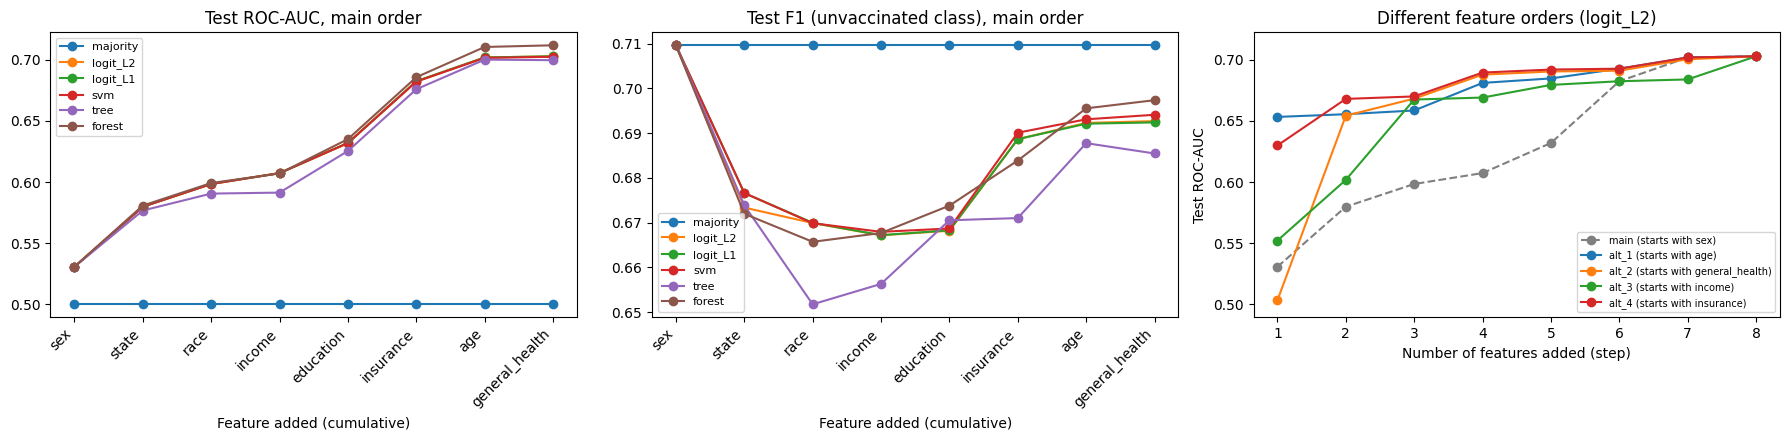

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Panels 1 and 2: all models, main order
for name, res in tier_results.items():
    axes[0].plot(res.index, res["roc_auc"], marker="o", label=name)
    axes[1].plot(res.index, res["f1"], marker="o", label=name)

for ax, title in zip(axes[:2], ["Test ROC-AUC", "Test F1 (unvaccinated class)"]):
    ax.set_xticks(range(1, len(tier_order) + 1))
    ax.set_xticklabels(tier_order, rotation=45, ha="right")
    ax.set_title(f"{title}, main order")
    ax.set_xlabel("Feature added (cumulative)")
    ax.legend(fontsize=8)

# Panel 3: logit_L2 under each order, plotted by step number
ax = axes[2]
for k, res in order_results.items():
    style = dict(linestyle="--", color="gray") if k == "main" else {}
    ax.plot(res.index, res["roc_auc"], marker="o",
            label=f"{k} (starts with {orders[k][0]})", **style)
ax.set_xticks(range(1, len(tier_order) + 1))
ax.set_xlabel("Number of features added (step)")
ax.set_ylabel("Test ROC-AUC")
ax.set_title("Different feature orders (logit_L2)")
ax.set_ylim(axes[0].get_ylim())
ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

Fit models one more time for more metrics

In [23]:
final_models = {
    "majority": (DummyClassifier(strategy="prior"), "lr"),
    "logit_L2": (best["logit_L2"], "lr"),
    "logit_L1": (best["logit_L1"], "lr"),
    "svm":      (best["svm"], "lr"),
    "tree":     (best_tree["tree"], "tree"),
    "forest":   (best_tree["forest"], "tree"),
}
mats = {"lr": (Xlr_train, Xlr_test), "tree": (Xtree_train, Xtree_test)}

fitted, probs, train_probs = {}, {}, {}
for name, (clf, key) in final_models.items():
    Xtr, Xte = mats[key]
    m = clone(clf).fit(Xtr, y_train)          # full training set, tuned settings
    fitted[name] = m
    probs[name] = m.predict_proba(Xte)[:, 1]  # P(vaccinated) on the test set
    train_probs[name] = m.predict_proba(Xtr)[:, 1]
    print("fitted", name)

fitted majority
fitted logit_L2
fitted logit_L1
fitted svm
fitted tree
fitted forest


the results:

In [24]:
from sklearn.metrics import precision_score, recall_score

n = len(y_test)
baseline_acc = max(y_test.mean(), 1 - y_test.mean())

# bootstrap CI for AUC (200 resamples of the test set; reuses stored probabilities)
rng = onp.random.RandomState(SEED)
boot_idx = [rng.randint(0, n, n) for _ in range(200)]
def auc_ci(p):
    return onp.percentile([roc_auc_score(y_test[i], p[i]) for i in boot_idx], [2.5, 97.5])

rows = {}
for name, p in probs.items():
    pred = (p >= 0.5).astype(int)
    lo, hi = auc_ci(p)
    acc = accuracy_score(y_test, pred)
    rows[name] = {
        "accuracy":        acc,
        "acc_vs_baseline": acc - baseline_acc,
        "roc_auc":         roc_auc_score(y_test, p),
        "auc_95ci":        f"[{lo:.3f}, {hi:.3f}]",
        "train_auc":       roc_auc_score(y_train, train_probs[name]),
        "prec_unvax":      precision_score(y_test, pred, pos_label=0, zero_division=0),
        "rec_unvax":       recall_score(y_test, pred, pos_label=0),
        "f1_unvax":        f1_score(y_test, pred, pos_label=0),
        "log_loss":        log_loss(y_test, p),
    }

results = pd.DataFrame.from_dict(rows, orient="index").round(4)
print("Majority-class accuracy on test:", round(baseline_acc, 4))
results

Majority-class accuracy on test: 0.5499


,accuracy,acc_vs_baseline,roc_auc,auc_95ci,train_auc,prec_unvax,rec_unvax,f1_unvax,log_loss
majority,0.5499,0.0000,0.5000,"[0.500, 0.500]",0.5000,0.5499,1.0000,0.7096,0.6882
logit_L2,0.6509,0.1009,0.7029,"[0.699, 0.708]",0.7024,0.6713,0.7155,0.6927,0.6236
logit_L1,0.6505,0.1006,0.7029,"[0.699, 0.708]",0.7024,0.6710,0.7152,0.6924,0.6236
svm,0.6509,0.1010,0.7025,"[0.698, 0.707]",0.7019,0.6699,0.7202,0.6941,0.6237
tree,0.6471,0.0971,0.6997,"[0.695, 0.705]",0.7031,0.6722,0.6993,0.6855,0.6246
forest,0.6555,0.1056,0.7119,"[0.708, 0.717]",0.7280,0.6746,0.7217,0.6974,0.6164


Age seems to be the strongest predictor, so let's determine which age is least likely to be vaccinated

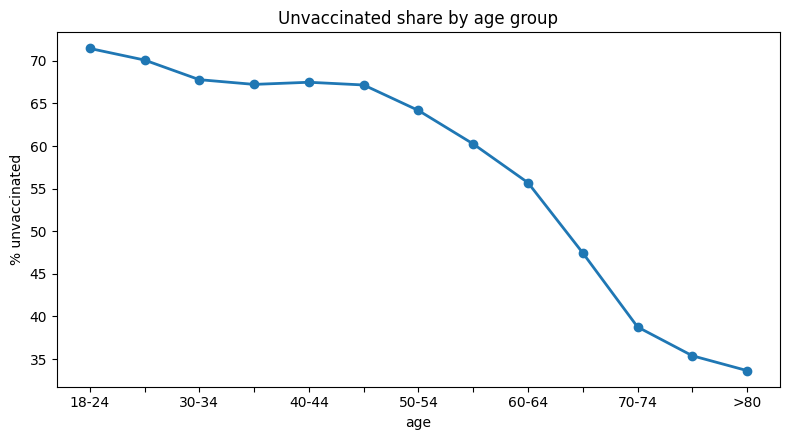

In [25]:
unvax_by_age = (1 - data.groupby('age', observed=True)['flu'].mean()) * 100

ax = unvax_by_age.plot(marker='o', lw=2, figsize=(8,4.5))
ax.set_xticks(range(len(unvax_by_age)))
ax.set_ylabel('% unvaccinated')
ax.set_title('Unvaccinated share by age group')
plt.tight_layout()
plt.show()

Subgroup Analysis

In [26]:
test_df = data.loc[Xtree_test.index].copy()
test_df['p'] = probs['forest']
test_df['y'] = y_test

def subgroup_table(col):
  rows = []
  for lv, g in test_df.groupby(col, observed=True):
    if g['y'].nunique() < 2 or len(g) < 200: continue
    rows.append({col : lv,
                 'n': len(g),
                 'observed_vax':g['y'].mean(),
                 'mean_predicted': g['p'].mean(),
                 'auc': roc_auc_score(g['y'], g['p']),
                 'recall_unvax': ((g['p'] <0.5) & (g['y']==0)).sum()/(g['y']==0).sum()})
  return pd.DataFrame(rows).set_index(col).round(3)

for c in ['age', 'sex', 'race', 'insurance']:
  print(f"\n--- {c} ---")
  print(subgroup_table(c))


--- age ---
          n  observed_vax  mean_predicted    auc  recall_unvax
age                                                           
18-24  2996         0.282           0.273  0.633         0.990
25-29  2833         0.296           0.310  0.690         0.963
30-34  2983         0.335           0.325  0.704         0.927
35-39  3415         0.323           0.335  0.722         0.898
40-44  3635         0.327           0.338  0.694         0.913
45-49  3624         0.311           0.343  0.685         0.905
50-54  3682         0.367           0.358  0.649         0.890
55-59  4124         0.400           0.397  0.633         0.843
60-64  4992         0.442           0.435  0.629         0.787
65-69  5610         0.530           0.531  0.625         0.534
70-74  5304         0.608           0.612  0.627         0.191
75-79  4507         0.645           0.642  0.614         0.093
>80    4824         0.669           0.644  0.633         0.051

--- sex ---
            n  observed_vax  

Feature Importance -- testing how much worse a model is without each feature

                logit_L2    tree  forest
age               0.0719  0.1348  0.1168
insurance         0.0287  0.0075  0.0141
education         0.0284  0.0423  0.0392
state             0.0178  0.0005  0.0053
income            0.0089  0.0128  0.0139
sex               0.0054  0.0058  0.0078
race              0.0022  0.0007  0.0028
general_health    0.0021  0.0011  0.0035


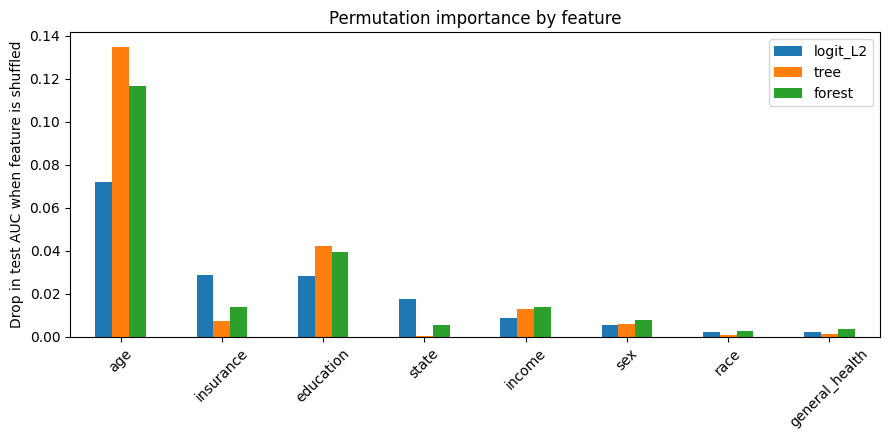

Rank correlation between models:
          logit_L2  tree  forest
logit_L2      1.00  0.64    0.88
tree          0.64  1.00    0.90
forest        0.88  0.90    1.00


In [27]:
def group_perm_importance(model, Xte, yte, feats, n_repeats=5, seed=SEED):
    rng = onp.random.RandomState(seed)
    base = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
    out = {}
    for f in feats: #loop over features
        cols = cols_for([f], Xte.columns)
        drops = []
        for _ in range(n_repeats):
            Xp = Xte.copy()
            Xp[cols] = Xte[cols].values[rng.permutation(len(Xte))]
            drops.append(base - roc_auc_score(yte, model.predict_proba(Xp)[:, 1]))
        out[f] = (onp.mean(drops), onp.std(drops))
    return pd.DataFrame(out, index=["auc_drop", "sd"]).T

feats = tier_order
perm = {
    "logit_L2": group_perm_importance(fitted["logit_L2"], Xlr_test,   y_test, feats),
    "tree":     group_perm_importance(fitted["tree"],     Xtree_test, y_test, feats),
    "forest":   group_perm_importance(fitted["forest"],   Xtree_test, y_test, feats),
}
perm_table = pd.DataFrame({k: v["auc_drop"] for k, v in perm.items()}).sort_values("logit_L2", ascending=False)
print(perm_table.round(4))

perm_table.plot.bar(figsize=(9, 4.5), rot=45)
plt.ylabel("Drop in test AUC when feature is shuffled")
plt.title("Permutation importance by feature")
plt.tight_layout(); plt.show()

print("Rank correlation between models:")
print(perm_table.rank().corr(method="spearman").round(2))

Error Analysis

logit_L2 | unvax caught: 20668 | unvax missed: 8220 | vax flagged as unvax: 10119 | vax correct: 13522
forest | unvax caught: 20848 | unvax missed: 8040 | vax flagged as unvax: 10055 | vax correct: 13586


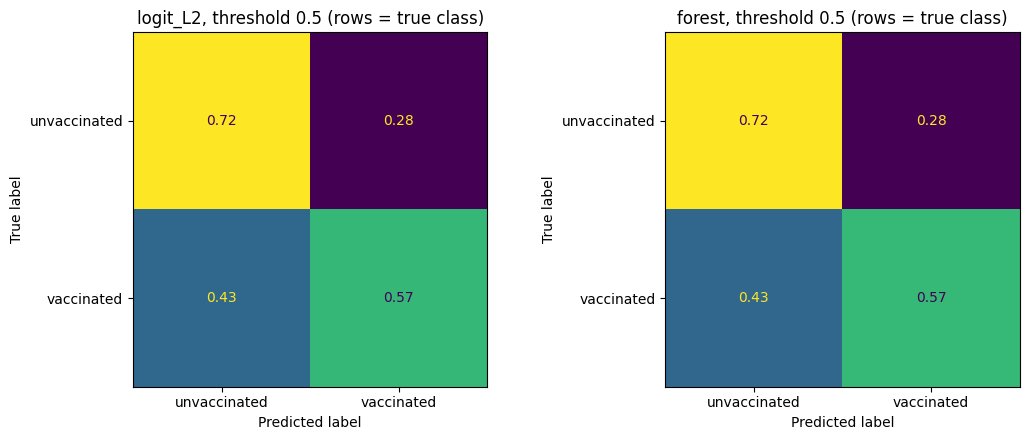

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["logit_L2", "forest"]):
    pred = (probs[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    print(name, "| unvax caught:", cm[0,0], "| unvax missed:", cm[0,1],
          "| vax flagged as unvax:", cm[1,0], "| vax correct:", cm[1,1])
    ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize="true", values_format=".2f",
        display_labels=["unvaccinated", "vaccinated"], ax=ax, colorbar=False)
    ax.set_title(f"{name}, threshold 0.5 (rows = true class)")
plt.tight_layout(); plt.show()